# Ranking Senior Men's National Football Teams and Predicting the 2026 World Cup

I was recently invited by my department to participate in a World Cup prediction competitition. We'd predict how we thought each group would end up, which third place teams would do well enough to advance to the knockouts, and how the final knockout bracket would work.

I filled out a bracket and got 5th place, a finish I'm quite happy with. My question now is if I could've done better. If I had the data on each team's prior performance, could I predict the World Cup better? Could I also, in the process, get a sense of which teams are just generally stronger and which teams are weaker?

This is what we'll do in this notebook: try out a few different ways of ranking teams, and try a few different simulation methods to predict results.

We start by loading in our libraries and data. The dataset we're working from contains every major international men's senior football match from the first friendly in Glasgow in 1872 to the 2026 World Cup Final in New Jersey.

In [101]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import copy
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from pandas.api.types import CategoricalDtype
import seaborn as sns
data = pd.read_csv("results.csv")
conditions = [
    data['home_score'] > data['away_score'],
    data['home_score'] == data['away_score'],
    data['home_score'] < data['away_score']
]

choices = ['home_win', 'draw', 'away_win']
data['result'] = np.select(conditions, choices, default='Unknown')
result_type = CategoricalDtype(
    categories=choices[::-1], 
    ordered=True
)
data['result'] = data['result'].astype(result_type)
data.head()


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,result
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False,draw
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False,home_win
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False,home_win
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False,draw
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False,home_win


## Rating and ranking teams

The first task we'll be doing is comparing three ways to rate and rank men's football teams based on their past performances. When rating teams, we're going to only consider matches from before the 2026 World Cup.

### Elo

Our first method of rating teams will be the Elo method. The basic idea is that the difference in two teams' ratings corresponds to how likely they are to win a match, and ratings are adjusted based on the difference between the predicted result and the actual result. More high-stakes games (the World Cup, continental championships) are weighted higher, and when there's a home team advantage, the win probabilities are adjusted appropriately.

The below cell does all of the computations needed to assign an Elo score.

In [102]:
lands = [x for x in set(data['home_team']).union(set(data['away_team'])) if pd.notna(x)]
lands.sort()
scores = [1000 for i in range(len(lands))]
score_table = pd.DataFrame({"country": lands, "score": scores})
score_table.set_index('country', inplace=True)

ordinal_list = []

def fg(h, a):
    diff = abs(h-a)
    if diff <= 1:
        return 1
    elif diff == 2:
        return 1.5
    else:
        return (11 + diff) / 8
    
def fw(x, y):
    diff = x - y
    if diff < 0:
        return 0
    elif diff == 0:
        return 0.5
    else:
        return 1
    
def fk(tournament):
    if tournament in ["Olympic Games", "FIFA World Cup"]:
        return 60
    elif tournament in ["AFC Asian Cup", "African Cup of Nations", "CONCACAF Championship", "Gold Cup", "Copa América", "Oceania Nations Cup", "UEFA Euro", "CONMEBOL–UEFA Cup of Champions", "Confederations Cup"]:
        return 50
    elif tournament in ["FIFA World Cup qualification", "AFC Asian Cup qualification", "UEFA Euro qualification", "African Cup of Nations qualification", "CONCACAF Championship qualification", "Copa América qualification", "Gold Cup qualification", "Oceania Nations Cup qualification"]:
        return 40
    elif tournament == "Friendly":
        return 20
    else:
        return 30


for x in data.itertuples(index=False):
    if pd.isna(x.home_score) or pd.isna(x.away_score):
        continue
    if (int(x.date[:4]) == 2026) and x.tournament == "FIFA World Cup":
        break
    dr = score_table.loc[x.home_team, 'score'] - score_table.loc[x.away_team, 'score']
    if not x.neutral:
        dr += 100
    expectation_home = 1/(100**(-dr/400) + 1)
    expectation_away = 1 - expectation_home
    g = fg(x.home_score, x.away_score)
    k = fk(x.tournament)
    result_home = fw(x.home_score, x.away_score)
    result_away = fw(x.away_score, x.home_score)
    change_home = k * g * (result_home - expectation_home)
    change_away = k * g * (result_away - expectation_away)
    ordinal_list.append({"elo_diff": score_table.loc[x.home_team, 'score'] - score_table.loc[x.away_team, 'score'], "neutral": x.neutral, "result": x.result})
    score_table.loc[x.home_team, 'score'] = score_table.loc[x.home_team, 'score'] + change_home
    score_table.loc[x.away_team, 'score'] = score_table.loc[x.away_team, 'score'] + change_away
    print(x.home_team, x.home_score, x.away_team, x.away_score)

final_table_elo = score_table.sort_values(by="score", ascending = False)
final_table_elo.rename(columns = {"score": "rating"}, inplace=True)
final_table_elo.head(10)

/var/folders/5l/029x820d3hjgnct_bv_xsyzr0000gn/T/ipykernel_45940/516680384.py:57: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '994.8050614670408' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  score_table.loc[x.home_team, 'score'] = score_table.loc[x.home_team, 'score'] + change_home


Scotland 0 England 0
England 4 Scotland 2
Scotland 2 England 1
England 2 Scotland 2
Scotland 3 England 0
Scotland 4 Wales 0
England 1 Scotland 3
Wales 0 Scotland 2
Scotland 7 England 2
Scotland 9 Wales 0
England 2 Wales 1
England 5 Scotland 4
Wales 0 Scotland 3
Scotland 5 England 4
Wales 2 England 3
Scotland 5 Wales 1
England 0 Wales 1
England 1 Scotland 6
Wales 1 Scotland 5
Northern Ireland 0 England 13
Wales 7 Northern Ireland 1
Scotland 5 England 1
Wales 5 England 3
Scotland 5 Wales 0
England 5 Wales 0
England 7 Northern Ireland 0
England 2 Scotland 3
Wales 0 Scotland 3
Northern Ireland 1 Wales 1
Northern Ireland 0 Scotland 5
Wales 6 Northern Ireland 0
Northern Ireland 1 England 8
Scotland 1 England 0
Wales 0 England 4
Scotland 4 Wales 1
England 4 Northern Ireland 0
England 1 Wales 1
Scotland 8 Northern Ireland 2
England 1 Scotland 1
Wales 1 Scotland 8
Northern Ireland 2 Wales 8
United States 0 Canada 1
Wales 5 Northern Ireland 0
Northern Ireland 1 England 6
Northern Ireland 2 Scotl

,rating
country,
Spain,1457.504511
Argentina,1413.053256
France,1379.922063
England,1373.419129
Brazil,1349.252256
Ecuador,1349.185227
Colombia,1342.657191
Turkey,1333.511981
Norway,1324.311161


The above table has the top rated teams' Elos. As you can see, the four top rated teams by Elo happened to be the teams that played the semifinals of the World Cup this year.

### Markov

The next method of rating teams works as follows. We construct a directed graph where for every goal conceded by team A to team B, the weight of the edge pointing from team A to team B increases by 1. We then find the corresponding transition (or Markov) matrix and find its dominant eigenvector. The dominant eigenvector gives an indication of how likely a random walker on this graph is to end up at a specific node in the long run. The value in the dominant eigenvector corresponding to each node/team indicates how highly rated that team is.

One important thing: only the most recent matches actually cause the weights of edges to increase by 1 (or a value close to 1). The earlier the match, the lesser of a weight it has.

In [103]:
def fweight(x, sharpness = 20):
    return (1/sharpness) * (sharpness ** ((x- 1872)/154))

scoring_matrix = pd.DataFrame(np.zeros((len(lands), len(lands))), index=lands, columns=lands)
for x in data.itertuples(index=False):
    if pd.isna(x.home_score) or pd.isna(x.away_score):
            continue
    if (int(x.date[:4]) == 2026) and x.tournament == "FIFA World Cup":
            break
    weight = fweight(int(x.date[:4]))
    print(x.home_team, x.home_score, x.away_team, x.away_score)
    scoring_matrix.loc[x.home_team, x.away_team] += x.away_score * weight
    scoring_matrix.loc[x.away_team, x.home_team] += x.home_score * weight

arr = scoring_matrix.to_numpy()
zero_rows_mask = np.all(arr == 0, axis=1)
arr[zero_rows_mask] = np.full(len(lands), 1)
row_sums = arr.sum(axis=1, keepdims=True)
arr = arr / row_sums

eigenvals, eigenvecs = np.linalg.eig(arr.T)
idx = np.argmin(abs(eigenvals - 1))
result = eigenvecs[:,idx].real
if np.any(result < 0):
    prev = np.full(len(lands),1)
    curr = arr.T @ prev
    iter = 0
    while sum(abs(curr - prev)) > 0.000000001 and iter <= 100000:
        prev = curr
        curr = arr.T @ curr
        iter += 1
    result = curr
     
final_table_markov = pd.DataFrame(index = lands, data = result, columns = ["rating"]).sort_values(by = "rating", ascending = False)
final_table_markov.head(10)


Scotland 0 England 0
England 4 Scotland 2
Scotland 2 England 1
England 2 Scotland 2
Scotland 3 England 0
Scotland 4 Wales 0
England 1 Scotland 3
Wales 0 Scotland 2
Scotland 7 England 2
Scotland 9 Wales 0
England 2 Wales 1
England 5 Scotland 4
Wales 0 Scotland 3
Scotland 5 England 4
Wales 2 England 3
Scotland 5 Wales 1
England 0 Wales 1
England 1 Scotland 6
Wales 1 Scotland 5
Northern Ireland 0 England 13
Wales 7 Northern Ireland 1
Scotland 5 England 1
Wales 5 England 3
Scotland 5 Wales 0
England 5 Wales 0
England 7 Northern Ireland 0
England 2 Scotland 3
Wales 0 Scotland 3
Northern Ireland 1 Wales 1
Northern Ireland 0 Scotland 5
Wales 6 Northern Ireland 0
Northern Ireland 1 England 8
Scotland 1 England 0
Wales 0 England 4
Scotland 4 Wales 1
England 4 Northern Ireland 0
England 1 Wales 1
Scotland 8 Northern Ireland 2
England 1 Scotland 1
Wales 1 Scotland 8
Northern Ireland 2 Wales 8
United States 0 Canada 1
Wales 5 Northern Ireland 0
Northern Ireland 1 England 6
Northern Ireland 2 Scotl

,rating
Brazil,9.821879
Germany,9.063721
Argentina,7.955380
England,7.626566
France,7.363594
Netherlands,7.071519
Spain,6.979672
Sweden,6.277947
Italy,6.166369
Belgium,5.791804


Not the craziest ranking, but probably not the ranking most reflective of recent team performances, either.

### Offense-Defense ratings

The final method calculates an offensive rating for each team, uses that offensive rating to calculate a defensive rating, and iteratively updates the offensive and defensive ratings back and forth until the ratings stabilize and converge. If it takes too long for the ratings to converge, I have also included a manual stop after 10000 iterations. Again, only recent matches are weighted highly.

In [104]:
scoring_matrix = pd.DataFrame(np.zeros((len(lands), len(lands))), index=lands, columns=lands)
match_matrix = pd.DataFrame(np.zeros((len(lands), len(lands))), index=lands, columns=lands)
for x in data.itertuples(index=False):
    if pd.isna(x.home_score) or pd.isna(x.away_score):
            continue
    if (int(x.date[:4]) == 2026) and x.tournament == "FIFA World Cup":
            break
    weight = fweight(int(x.date[:4]) - 1872)
    print(x.home_team, x.home_score, x.away_team, x.away_score)
    scoring_matrix.loc[x.home_team, x.away_team] += x.away_score * weight
    scoring_matrix.loc[x.away_team, x.home_team] += x.home_score * weight
    match_matrix.loc[x.home_team, x.away_team] += 1 * weight
    match_matrix.loc[x.away_team, x.home_team] += 1 * weight

score_count = scoring_matrix.to_numpy()
match_count = match_matrix.to_numpy()
match_count[match_count == 0] = 1
a = score_count / match_count

d = np.full(len(lands), 1)
o = np.full(len(lands), 1)

prev_o = o
prev_d = d

a = a + 0.01
o = a.T @ (1/d)
d = a @ (1/o)
iter = 1

while (sum(abs(prev_o - o)) > 10 or sum(abs(prev_d - d)) > 10) and iter < 10000:
    o = a.T @ (1/d)
    d = a @ (1/o)
    iter += 1

final_table_od = pd.DataFrame(index = lands, data = o/d, columns = ["rating"]).sort_values(by = "rating", ascending = False)
final_table_od.head(10)


Scotland 0 England 0
England 4 Scotland 2
Scotland 2 England 1
England 2 Scotland 2
Scotland 3 England 0
Scotland 4 Wales 0
England 1 Scotland 3
Wales 0 Scotland 2
Scotland 7 England 2
Scotland 9 Wales 0
England 2 Wales 1
England 5 Scotland 4
Wales 0 Scotland 3
Scotland 5 England 4
Wales 2 England 3
Scotland 5 Wales 1
England 0 Wales 1
England 1 Scotland 6
Wales 1 Scotland 5
Northern Ireland 0 England 13
Wales 7 Northern Ireland 1
Scotland 5 England 1
Wales 5 England 3
Scotland 5 Wales 0
England 5 Wales 0
England 7 Northern Ireland 0
England 2 Scotland 3
Wales 0 Scotland 3
Northern Ireland 1 Wales 1
Northern Ireland 0 Scotland 5
Wales 6 Northern Ireland 0
Northern Ireland 1 England 8
Scotland 1 England 0
Wales 0 England 4
Scotland 4 Wales 1
England 4 Northern Ireland 0
England 1 Wales 1
Scotland 8 Northern Ireland 2
England 1 Scotland 1
Wales 1 Scotland 8
Northern Ireland 2 Wales 8
United States 0 Canada 1
Wales 5 Northern Ireland 0
Northern Ireland 1 England 6
Northern Ireland 2 Scotl

,rating
Brazil,442.785360
England,375.183042
Spain,374.553735
Argentina,366.775026
Germany,311.069137
France,310.815256
Australia,269.535090
Netherlands,261.295469
Portugal,255.916090
Yugoslavia,255.152013


Again, not the craziest ratings, although there are a few eyebrow-raising entries in the top 10 (like Australia [no offense to the Socceroos of course]).

## Predicting Match Results

Now we shift gears to using models that aim to simulate and predict the result of a game.

### Poisson

We start by treating the number of goals each team scores in a match as a Poisson random variable, and we use Poisson regression on prior matches (from 2018 to right before the 2026 World Cup) to find the average scoring rates.

In [105]:
filtered_data = data[data["date"].apply(lambda x: int(x[:4]) >= 2018)]
filtered_data = filtered_data[filtered_data["tournament"].apply(lambda x: fk(x) > 30)]
filtered_data = filtered_data[filtered_data["tournament"].apply(lambda x: x != 'FIFA World Cup') | filtered_data["date"].apply(lambda x: int(x[:4]) < 2026)]

reg_data = pd.concat([filtered_data[['home_team','away_team','home_score']].rename(
            columns={'home_team':'team', 'away_team':'opponent','home_score':'goals'}),
           filtered_data[['away_team','home_team','away_score']].rename(
            columns={'away_team':'team', 'home_team':'opponent','away_score':'goals'})])


poisson_model = smf.glm(formula="goals ~ team + opponent", data=reg_data,
                        family=sm.families.Poisson()).fit()

coefs = poisson_model.params
team = coefs[coefs.index.str.contains('team')]
team.index = team.index.str[7:-1]
opponent = coefs[coefs.index.str.contains('opponent')]
opponent.index = opponent.index.str[11:-1]

We then use this model to predict the results of a match. We predict what would happen if Spain and Portugal played one another.

/var/folders/5l/029x820d3hjgnct_bv_xsyzr0000gn/T/ipykernel_45940/1095507307.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  team_a[i]=np.random.poisson(home_score_rate)
/var/folders/5l/029x820d3hjgnct_bv_xsyzr0000gn/T/ipykernel_45940/1095507307.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  team_b[i]=np.random.poisson(away_score_rate)


[Text(0.5, 1.0, 'Probability map of different results in a Spain-Portugal match'),
 Text(0.5, 23.52222222222222, 'Portugal Goals'),
 Text(50.722222222222214, 0.5, 'Spain Goals')]

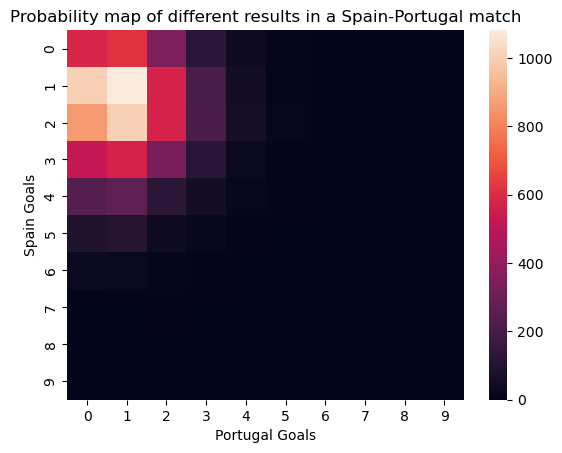

In [106]:

# Set teams here
home_team='Spain'
away_team='Portugal'

#Predict for Arsenal vs. Manchester City
home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': home_team, 'opponent': away_team,
                                       'home':1},index=[1]))

away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': away_team, 'opponent': home_team,
                                       'home':0},index=[1]))
(home_score_rate, away_score_rate)




team_a = np.zeros(10000)
team_b = np.zeros(10000)
for i in range(10000):
    team_a[i]=np.random.poisson(home_score_rate)
    team_b[i]=np.random.poisson(away_score_rate)

size = int(max(team_a.max(), team_b.max())) + 1
result = np.zeros((size, size))

team_a_win = 0
team_b_win = 0
draw = 0
for s, p in zip(team_a, team_b):
    result[int(s), int(p)] += 1
    if s > p:
        team_a_win += 1
    elif p > s:
        team_b_win += 1
    else:
        draw += 1

sns.heatmap(result).set(title="Probability map of different results in a Spain-Portugal match", xlabel="Portugal Goals", ylabel="Spain Goals")

Above we have a probabilistic heat map of how likely different results are in a match between Spain and Portugal. To see how likely a specific result is (e.g. a 1-1 draw), you find the number of goals you think Spain will score on the y-axis and the number of goals you think Portugal will score on the x-axis, and you look at how bright it is.

Below, we also have the probabilities of Portugal winning, a draw, and Spain winning, respectively.

In [107]:
print(team_b_win / 10000, draw / 10000, team_a_win / 10000)

0.233 0.2364 0.5306


### Elo (again)

Remember how I said that Elo ratings are based on how likely a team is to win or lose a match? It turns out we can use Elo ratings to predict match results and give win probabilities.

The standard Elo method doesn't allow you to predict a draw, so instead of using the default Elo win probability formula, we run an ordinal logistic regression on the Elo difference and whether there's a home/away effect to predict matches.

In [108]:
ordinal_table = pd.DataFrame(ordinal_list)
ordinal_table
ordinal_table['result'] = ordinal_table['result'].astype(result_type)
ordinal_table['neutral'] = ordinal_table['neutral'].astype(int)

model = OrderedModel(
    ordinal_table['result'], 
    ordinal_table[['elo_diff', 'neutral']], 
    distr='logit'
)
model_result = model.fit(method='bfgs', disp=False)
predictions = model_result.model.predict(model_result.params, exog=ordinal_table[['elo_diff', 'neutral']])


We then use the difference in Elo ratings between Spain and Portugal to get the probabilities of different outcomes in a Spain-Portugal match played at a neutral venue. Like the previous method, we have the probabilities of Portugal winning, a draw, and Spain winning, respectively.

In [109]:
model_result.model.predict(model_result.params, exog=[[final_table_elo.loc['Spain', 'rating'] - final_table_elo.loc['Portugal', 'rating'], True]])

array([[0.14188379, 0.21422604, 0.64389017]])

## Model Evaluation

We will now evaluate our models. We could do something rigorous and supported by statistical and machine learning methodology.

But I thought it'd be more fun to try to have our models predict the results of the World Cup. So this first cell below sets up the teams that played in this year's World Cup. It, more specifically, has the results from the World Cup, including how each group finished, which third-place teams were the best, and when teams that progressed to the knockout stage got knocked out.

In [110]:
groups = [['Mexico', 'South Africa', 'South Korea', 'Czech Republic'], ['Switzerland', 'Canada', 'Bosnia and Herzegovina', 'Qatar'], ['Brazil', 'Morocco', 'Scotland', 'Haiti'], ['United States', 'Australia', 'Paraguay',  'Turkey'], ['Germany', 'Ecuador', 'Ivory Coast', 'Curaçao'], ['Netherlands', 'Japan', 'Sweden', 'Tunisia'], ['Belgium', 'Egypt', 'Iran', 'New Zealand'], ['Spain', 'Cape Verde', 'Uruguay', 'Saudi Arabia'], ['France', 'Norway', 'Senegal', 'Iraq'], ['Argentina', 'Austria', 'Algeria', 'Jordan'], ['Colombia', 'Portugal', 'DR Congo', 'Uzbekistan'], ['England', 'Croatia', 'Ghana', 'Panama']]
thirds = ['DR Congo', 'Sweden', 'Ghana', 'Ecuador', 'Bosnia and Herzegovina', 'Algeria', 'Paraguay', 'Senegal']

third_table = pd.read_csv('third.csv', header=None)
third_table.index = third_table.iloc[:, 0]
third_table = third_table.astype(str)
third_table.replace("nan", "", inplace=True)
third_table['key'] = third_table.iloc[:,1:13].agg(''.join, axis=1)
third_table['value'] = third_table.iloc[:,13:-1].agg(''.join, axis=1).apply(lambda x: x[1::2])
third_table = third_table.loc[:, ['key','value']].set_index('key')

r32_matches = [['1E', 3], ['1I', 5], ['2A', '2B'], ['1F', '2C'], ['2K', '2L'], ['1H', '2J'], ['1D', 2], ['1G', 4], ['1C', '2F'], ['2E', '2I'], ['1A', 0], ['1L', 7], ['1J', '2H'], ['2D', '2G'], ['1B', 1], ['1K', 6]]
bracket_losers = [['Germany', 'Sweden', 'South Africa', 'Netherlands', 'Croatia', 'Austria', 'Bosnia and Herzegovina', 'Senegal', 'Japan', 'Ivory Coast', 'Ecuador', 'DR Congo', 'Cape Verde', 'Australia', 'Algeria', 'Ghana'],
 ['Paraguay', 'Canada', 'Portugal', 'United States', 'Brazil', 'Mexico', 'Egypt', 'Colombia'],
 ['Morocco', 'Belgium', 'Norway', 'Switzerland'],
 ['France', 'England']
]

### Predicting the World Cup with ratings

Now we set up our functions to have our rating models (Elo, Markov, Offense-Defense) predict the World Cup.

Here's how it works. We basically sort groups by their ratings and take the top two from each group to progress onto the knockouts, sort the third place teams by their ratings and pick the top eight to progress, and we have the higher-ranked team winning each knockout round until a champion is declared.

In [111]:
def predict_groups(ratings, results, r32):
    prediction = []
    third_place = []
    third_place_groups = []
    r16 = []
    quarters = []
    semis = []
    final = []
    winner = ''
    comparison_bracket = [[], [], [], []]
    for group in results:
        prediction.append(ratings[ratings.index.isin(group)].sort_values('rating', ascending=False).index.to_list())
    for group in prediction:
        third_place.append(group[2])
    third_place = ratings[ratings.index.isin(third_place)].sort_values('rating', ascending=False).index.to_list()[:8]
    for idx, group in enumerate(results):
        if not set(group).isdisjoint(set(third_place)):
            third_place_groups.append(chr(65 + idx))
    matches3rd = ['3' + x for x in third_table.loc[''.join(third_place_groups)][0]]
    for match in r32:
        if isinstance(match[1], int):
            match[1] = matches3rd[match[1]]
    for match in r32:
        for idx, team in enumerate(match):
            match[idx] = prediction[ord(team[1]) - 65][int(team[0]) - 1]
    for match in r32:
        temp = ratings[ratings.index.isin(match)].sort_values('rating', ascending=False).index.to_list()
        r16.append(temp[0])
        comparison_bracket[0].append(temp[1])
    r16 = [[r16[i], r16[i+1]] for i in range(0, len(r16)-1, 2)]
    for match in r16:
        temp = ratings[ratings.index.isin(match)].sort_values('rating', ascending=False).index.to_list()
        quarters.append(temp[0])
        comparison_bracket[1].append(temp[1])
    quarters = [[quarters[i], quarters[i+1]] for i in range(0, len(quarters)-1, 2)]
    for match in quarters:
        temp = ratings[ratings.index.isin(match)].sort_values('rating', ascending=False).index.to_list()
        semis.append(temp[0])
        comparison_bracket[2].append(temp[1])
    semis = [[semis[i], semis[i+1]] for i in range(0, len(semis)-1, 2)]
    for match in semis:
        temp = ratings[ratings.index.isin(match)].sort_values('rating', ascending=False).index.to_list()
        final.append(temp[0])
        comparison_bracket[3].append(temp[1])
    final = [final]
    winner = ratings[ratings.index.isin(final[0])].sort_values('rating', ascending=False).index.to_list()[0]
    return prediction, third_place, [r32, r16, quarters, semis, final], comparison_bracket, winner



def score_model(prediction):
    pred_groups, pred_thirds, pred_bracket, pred_bracket_losers, pred_winner = prediction
    score = 0
    for group, pred_group in zip(groups, pred_groups):
        if group == pred_group:
            score += 60
        else:
            if group[0] == pred_group[0]:
                score += 20
            if group[1] == pred_group[1]:
                score += 10
            if group[2] == pred_group[2]:
                score += 10
    score += 10 * len(set(thirds).intersection(set(pred_thirds)))
    score += 30 * len(set(bracket_losers[0]).intersection(set(pred_bracket_losers[0])))
    score += 50 * len(set(bracket_losers[1]).intersection(set(pred_bracket_losers[1])))
    score += 80 * len(set(bracket_losers[2]).intersection(set(pred_bracket_losers[2])))
    score += 120 * len(set(bracket_losers[3]).intersection(set(pred_bracket_losers[3])))
    if pred_winner == 'Spain':
        score += 400
    return pred_groups, pred_thirds, pred_bracket, pred_winner, score



Now we actually have our rating models predict the World Cup. Here's how the scoring works. (It's based off of wcpredictor.app's scoring.)

For each group, predicting the correct first place team gets you 20 points, and predicting the correct second place and third place team gets you ten points each. If you predict a group perfectly, you get a bonus 20 points, for a maximum of 60 points per group and 720 for all 12 groups.

For each of the best third-place teams you correctly predict, you get 10 points.

For each team you correctly predict gets knocked out during the round of 32, you get 40 points.

For each team you correctly predict gets knocked out during the round of 16, you get 50 points.

For each team you correctly predict gets knocked out during the quarterfinals, you get 80 points.

For each team you correctly predict gets knocked out during the semifinals, you get 120 points.

And for correctly predicting the winner of it all, you get 400 points.

My bracket managed to get 1870 points and finished 5th in my department.  Our top scorer got 2000 points.

The top score globally was 2340 points, while the maximum possible score was 2640 points.

The median score was roughly 1290-1300.


In [112]:
prediction_elo = predict_groups(final_table_elo, groups, copy.deepcopy(r32_matches))
prediction_markov = predict_groups(final_table_markov, groups, copy.deepcopy(r32_matches))
prediction_od = predict_groups(final_table_od, groups, copy.deepcopy(r32_matches))


print("Elo predicted champion:", prediction_elo[-1])
print("Elo prediction score:", score_model(prediction_elo)[-1])
print("Markov predicted champion:", prediction_markov[-1])
print("Markov prediction score:", score_model(prediction_markov)[-1])
print("Offense-Defense predicted champion:", prediction_od[-1])
print("Offense-Defense prediction score:", score_model(prediction_od)[-1])

Elo predicted champion: Spain
Elo prediction score: 1430
Markov predicted champion: Brazil
Markov prediction score: 960
Offense-Defense predicted champion: Brazil
Offense-Defense prediction score: 740


/var/folders/5l/029x820d3hjgnct_bv_xsyzr0000gn/T/ipykernel_45940/1134073095.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  matches3rd = ['3' + x for x in third_table.loc[''.join(third_place_groups)][0]]


Our Elo model did the best job of predicting the tournament, and beat the median user. It did not beat me, a complete noob fan.

Here are the knockout brackets from the quarterfinals onwards from the Elo model, the Markov model, and the Offense-Defense model, respectively.

<img src="elo.png" width="20%"> <img src="markov.png" width="20%"> <img src="offensedefense.png" width="20%">

### Predicting the World Cup with simulation methods

Now, with our simulation models, we won't rate and rank each team to predict results. Instead, we'll simulate each individual match to do so. 

In [113]:
world_cup_group = data[(data['date'].apply(lambda x: int(x[:4])) == 2026) & (data['tournament'] == 'FIFA World Cup')][:72]
world_cup_knockout = data[(data['date'].apply(lambda x: int(x[:4])) == 2026) & (data['tournament'] == 'FIFA World Cup')][72:]
world_cup_group['projection'] = np.nan
world_cup_group.head(10)

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,result,projection
49416,2026-06-11,Mexico,South Africa,2,0,FIFA World Cup,Mexico City,Mexico,False,home_win,NaN
49417,2026-06-11,South Korea,Czech Republic,2,1,FIFA World Cup,Zapopan,Mexico,True,home_win,NaN
49418,2026-06-12,Canada,Bosnia and Herzegovina,1,1,FIFA World Cup,Toronto,Canada,False,draw,NaN
49419,2026-06-12,United States,Paraguay,4,1,FIFA World Cup,Inglewood,United States,False,home_win,NaN
49420,2026-06-13,Qatar,Switzerland,1,1,FIFA World Cup,Santa Clara,United States,True,draw,NaN
49421,2026-06-13,Brazil,Morocco,1,1,FIFA World Cup,East Rutherford,United States,True,draw,NaN
49422,2026-06-13,Haiti,Scotland,0,1,FIFA World Cup,Foxborough,United States,True,away_win,NaN
49423,2026-06-13,Australia,Turkey,2,0,FIFA World Cup,Vancouver,Canada,True,home_win,NaN
49424,2026-06-14,Germany,Curaçao,7,1,FIFA World Cup,Houston,United States,True,home_win,NaN
49425,2026-06-14,Ivory Coast,Ecuador,1,0,FIFA World Cup,Philadelphia,United States,True,home_win,NaN


Above is a table of the first 10 matches of the World Cup.

We start by letting our Elo model predict each match. From the implied win/draw/loss probabilities of each matchup, we simulate each match about 50 times and pick the most frequent winner. Any ties are broken by Elo rating.

At the very bottom is the champion and score from one prediction the Elo model makes. You can repeat these predictions over and over in a Monte Carlo-esque way to get a range of predictions and corresponding scores. I haven't made a bracket this time around since the predictions can change every time you run it.

In [114]:
def predict_groups_elo_sim(rng, n, r32):
    r16 = []
    quarters = []
    semis = []
    final = []
    winner = ''
    comparison_bracket = [[], [], [], []]
    group_scores = {team: 0 for group in groups for team in group}
    for fixture in world_cup_group.itertuples():
        home_elo = final_table_elo.loc[fixture.home_team, 'rating']
        away_elo = final_table_elo.loc[fixture.away_team, 'rating']
        probs = model_result.model.predict(model_result.params, exog=[[home_elo - away_elo, fixture.neutral]]).reshape(-1)
        match_result = pd.Series(rng.choice(['away_win', 'draw', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            group_scores[fixture.home_team] += 3
        elif match_result == 'away_win':
            group_scores[fixture.away_team] += 3
        else:
            group_scores[fixture.home_team] += 1
            group_scores[fixture.away_team] += 1

    group_dataframe = pd.DataFrame(index = group_scores.keys(), data = group_scores.values(), columns = ['score'])
    group_names = [char for l in [[char] * 4 for char in 'ABCDEFGHIJKL'] for char in l]
    group_dataframe['group'] = group_names
    group_dataframe['elo'] = group_dataframe.index.map(lambda x: final_table_elo.loc[x, 'rating'])
    group_dataframe.sort_values(by = ['group', 'score', 'elo'], inplace=True, ascending=[True,False, False])
    projected_third = group_dataframe.iloc[[i for i in range(2, 48, 4)]].sort_values(by = ['score', 'elo'], ascending = False).head(8)
    projected_third_matches = ['3' + x for x in third_table.loc[''.join(sorted(projected_third['group'].to_list()))]['value']]

    for match in r32:
        if isinstance(match[1], int):
            match[1] = projected_third_matches[match[1]]

    for match in r32:
        for idx, team in enumerate(match):
            match[idx] = group_dataframe[group_dataframe['group'] == team[1]].iloc[int(team[0]) - 1].name
    for match in r32:
        home_elo = final_table_elo.loc[match[0], 'rating']
        away_elo = final_table_elo.loc[match[1], 'rating']
        home_win_prob = 1/(1+10**((away_elo - home_elo)/400))
        probs = np.array([1-home_win_prob,home_win_prob])
        match_result = pd.Series(rng.choice(['away_win', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            r16.append(match[0])
            comparison_bracket[0].append(match[1])
        else:
            r16.append(match[1])
            comparison_bracket[0].append(match[0])
    r16 = [[r16[i], r16[i+1]] for i in range(0, len(r16)-1, 2)]
    for match in r16:
        home_elo = final_table_elo.loc[match[0], 'rating']
        away_elo = final_table_elo.loc[match[1], 'rating']
        home_win_prob = 1/(1+10**((away_elo - home_elo)/400))
        probs = np.array([1-home_win_prob,home_win_prob])
        match_result = pd.Series(rng.choice(['away_win', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            quarters.append(match[0])
            comparison_bracket[1].append(match[1])
        else:
            quarters.append(match[1])
            comparison_bracket[1].append(match[0])
    quarters = [[quarters[i], quarters[i+1]] for i in range(0, len(quarters)-1, 2)]

    for match in quarters:
        home_elo = final_table_elo.loc[match[0], 'rating']
        away_elo = final_table_elo.loc[match[1], 'rating']
        home_win_prob = 1/(1+10**((away_elo - home_elo)/400))
        probs = np.array([1-home_win_prob,home_win_prob])
        match_result = pd.Series(rng.choice(['away_win', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            semis.append(match[0])
            comparison_bracket[2].append(match[1])
        else:
            semis.append(match[1])
            comparison_bracket[2].append(match[0])
    semis = [[semis[i], semis[i+1]] for i in range(0, len(semis)-1, 2)]
    for match in semis:
        home_elo = final_table_elo.loc[match[0], 'rating']
        away_elo = final_table_elo.loc[match[1], 'rating']
        home_win_prob = 1/(1+10**((away_elo - home_elo)/400))
        probs = np.array([1-home_win_prob,home_win_prob])
        match_result = pd.Series(rng.choice(['away_win', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            final.append(match[0])
            comparison_bracket[3].append(match[1])
        else:
            final.append(match[1])
            comparison_bracket[3].append(match[0])
    final = [final]
    for match in final:
        home_elo = final_table_elo.loc[match[0], 'rating']
        away_elo = final_table_elo.loc[match[1], 'rating']
        home_win_prob = 1/(1+10**((away_elo - home_elo)/400))
        probs = np.array([1-home_win_prob,home_win_prob])
        match_result = pd.Series(rng.choice(['away_win', 'home_win'], p=probs, size = n)).mode().head(1).item()
        if match_result == 'home_win':
            winner = match[0]
        else:
            winner = match[1]

    third_place = projected_third.index.to_list()
    prediction = group_dataframe.index.to_list()
    prediction = [[prediction[i], prediction[i+1], prediction[i+2], prediction[i+3]] for i in range(0, 48, 4)]
    return prediction, third_place, [r32, r16, quarters, semis, final], comparison_bracket, winner

prediction_elo_sim = predict_groups_elo_sim(np.random.default_rng(), 50, copy.deepcopy(r32_matches))

score_model(prediction_elo_sim)[-2:]

('Spain', 1350)

We then let our Poisson model predict every match. Here, our Poisson model can literally simulate the number of goals scored, and we can simulate it over and over again to get the average number of goals scored. For the group stage, if, on average, a team scores more than half a goal than the other team, it wins the match, while any other result is counted as a draw. For the knockouts, the highest average score advances, regardless of how much it's higher by.

In [115]:
def predict_groups_pois_sim(n, r32):
    r16 = []
    quarters = []
    semis = []
    final = []
    winner = ''
    comparison_bracket = [[], [], [], []]
    group_scores = {team: 0 for group in groups for team in group}
    for fixture in world_cup_group.itertuples():
        home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': fixture.home_team, 'opponent': fixture.away_team,
                                       'home':1},index=[1]))

        away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': fixture.away_team, 'opponent': fixture.home_team,
                                            'home':0},index=[1]))
        home_score = np.random.poisson(home_score_rate, size = n).mean()
        away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score >= away_score + 0.5:
            group_scores[fixture.home_team] += 3
        elif home_score <= away_score - 0.5:
            group_scores[fixture.away_team] += 3
        else:
            group_scores[fixture.home_team] += 1
            group_scores[fixture.away_team] += 1

    group_dataframe = pd.DataFrame(index = group_scores.keys(), data = group_scores.values(), columns = ['score'])
    group_names = [char for l in [[char] * 4 for char in 'ABCDEFGHIJKL'] for char in l]
    group_dataframe['group'] = group_names
    group_dataframe['elo'] = group_dataframe.index.map(lambda x: final_table_elo.loc[x, 'rating'])
    group_dataframe.sort_values(by = ['group', 'score', 'elo'], inplace=True, ascending=[True,False, False])
    projected_third = group_dataframe.iloc[[i for i in range(2, 48, 4)]].sort_values(by = ['score', 'elo'], ascending = False).head(8)
    projected_third_matches = ['3' + x for x in third_table.loc[''.join(sorted(projected_third['group'].to_list()))]['value']]

    for match in r32:
        if isinstance(match[1], int):
            match[1] = projected_third_matches[match[1]]

    for match in r32:
        for idx, team in enumerate(match):
            match[idx] = group_dataframe[group_dataframe['group'] == team[1]].iloc[int(team[0]) - 1].name
    for match in r32:
        home_score, away_score = 0, 0
        while home_score == away_score:
            home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[0], 'opponent': match[1],
                                        'home':1},index=[1]))

            away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[1], 'opponent': match[0],
                                                'home':0},index=[1]))
            home_score = np.random.poisson(home_score_rate, size = n).mean()
            away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score > away_score:
            r16.append(match[0])
            comparison_bracket[0].append(match[1])
        elif home_score < away_score:
            r16.append(match[1])
            comparison_bracket[0].append(match[0])
    r16 = [[r16[i], r16[i+1]] for i in range(0, len(r16)-1, 2)]
    for match in r16:
        home_score, away_score = 0, 0
        while home_score == away_score:
            home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[0], 'opponent': match[1],
                                        'home':1},index=[1]))

            away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[1], 'opponent': match[0],
                                                'home':0},index=[1]))
            home_score = np.random.poisson(home_score_rate, size = n).mean()
            away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score > away_score:
            quarters.append(match[0])
            comparison_bracket[1].append(match[1])
        elif home_score < away_score:
            quarters.append(match[1])
            comparison_bracket[1].append(match[0])
    quarters = [[quarters[i], quarters[i+1]] for i in range(0, len(quarters)-1, 2)]

    for match in quarters:
        home_score, away_score = 0, 0
        while home_score == away_score:
            home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[0], 'opponent': match[1],
                                        'home':1},index=[1]))

            away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[1], 'opponent': match[0],
                                                'home':0},index=[1]))
            home_score = np.random.poisson(home_score_rate, size = n).mean()
            away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score > away_score:
            semis.append(match[0])
            comparison_bracket[2].append(match[1])
        elif home_score < away_score:
            semis.append(match[1])
            comparison_bracket[2].append(match[0])
    semis = [[semis[i], semis[i+1]] for i in range(0, len(semis)-1, 2)]
    for match in semis:
        home_score, away_score = 0, 0
        while home_score == away_score:
            home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[0], 'opponent': match[1],
                                        'home':1},index=[1]))

            away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[1], 'opponent': match[0],
                                                'home':0},index=[1]))
            home_score = np.random.poisson(home_score_rate, size = n).mean()
            away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score > away_score:
            final.append(match[0])
            comparison_bracket[3].append(match[1])
        elif home_score < away_score:
            final.append(match[1])
            comparison_bracket[3].append(match[0])
    final = [final]
    for match in final:
        home_score, away_score = 0, 0
        while home_score == away_score:     
            home_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[0], 'opponent': match[1],
                                        'home':1},index=[1]))

            away_score_rate=poisson_model.predict(pd.DataFrame(data={'team': match[1], 'opponent': match[0],
                                                'home':0},index=[1]))
            home_score = np.random.poisson(home_score_rate, size = n).mean()
            away_score = np.random.poisson(away_score_rate, size = n).mean()
        if home_score > away_score:
            winner = match[0]
        else:
            winner = match[1]

    third_place = projected_third.index.to_list()
    prediction = group_dataframe.index.to_list()
    prediction = [[prediction[i], prediction[i+1], prediction[i+2], prediction[i+3]] for i in range(0, 48, 4)]
    return prediction, third_place, [r32, r16, quarters, semis, final], comparison_bracket, winner

prediction_pois_sim = predict_groups_pois_sim(25, copy.deepcopy(r32_matches))

score_model(prediction_pois_sim)[-2:]

('Spain', 1500)

We now simulate the World Cup 100 times using each method and get the histogram of scores for each method as well as a bar plot of predicted winners for each method.

Text(0, 0.5, 'Frequency')

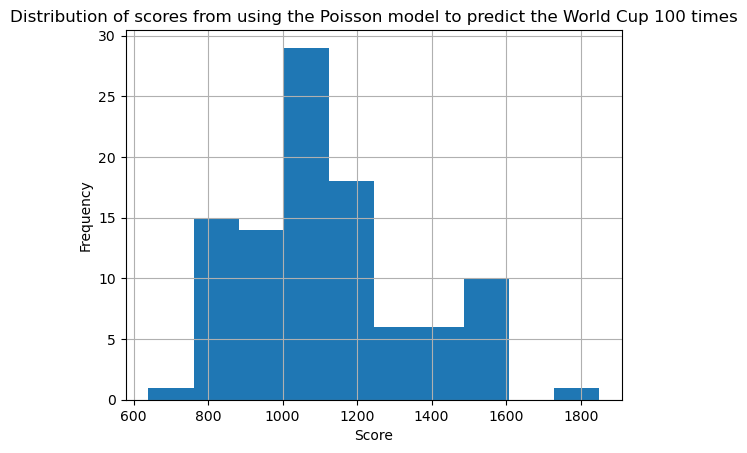

In [116]:
results = [score_model(predict_groups_pois_sim(50, copy.deepcopy(r32_matches)))[-2:] for i in range(100)]
results = pd.DataFrame(results, columns = ['winner', 'score'])
results['score'].hist()
plt.title("Distribution of scores from using the Poisson model to predict the World Cup 100 times")
plt.xlabel("Score")
plt.ylabel("Frequency")

Text(0.5, 0, 'Number of simulated World Cups they win')

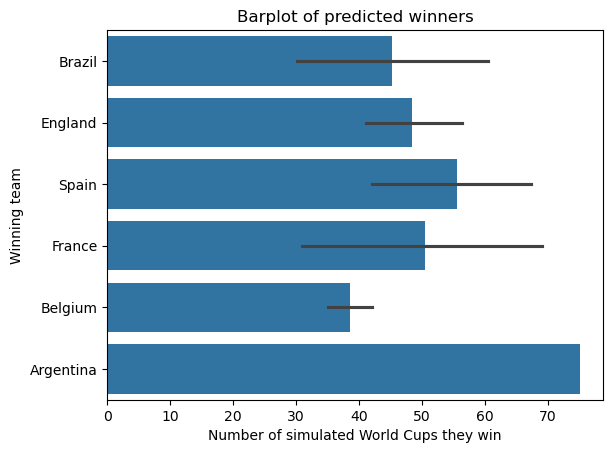

In [117]:
sns.barplot(results['winner'])
plt.title("Barplot of predicted winners")
plt.ylabel("Winning team")
plt.xlabel("Number of simulated World Cups they win")

Text(0, 0.5, 'Frequency')

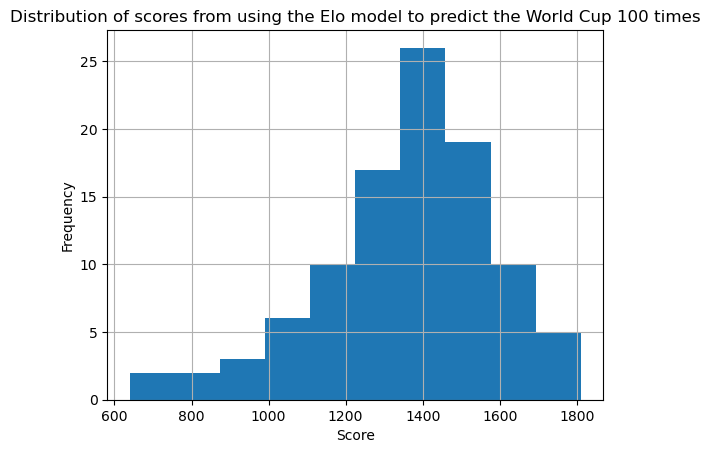

In [118]:
results = [score_model(predict_groups_elo_sim(np.random.default_rng(), 50, copy.deepcopy(r32_matches)))[-2:] for i in range(100)]
results = pd.DataFrame(results, columns = ['winner', 'score'])
results['score'].hist()
plt.title("Distribution of scores from using the Elo model to predict the World Cup 100 times")
plt.xlabel("Score")
plt.ylabel("Frequency")

Text(0.5, 0, 'Number of simulated World Cups they win')

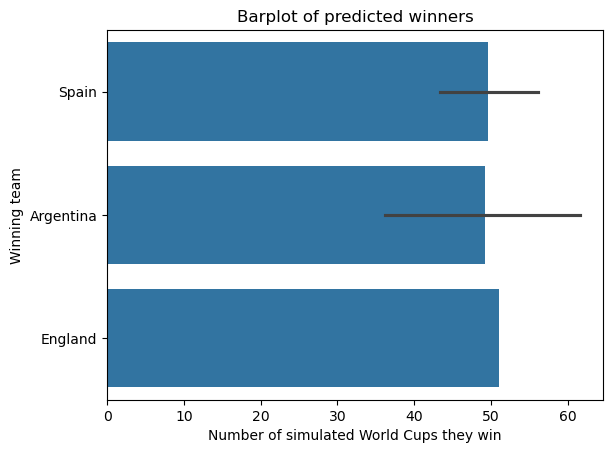

In [99]:
sns.barplot(results['winner'])
plt.title("Barplot of predicted winners")
plt.ylabel("Winning team")
plt.xlabel("Number of simulated World Cups they win")